## EX1

# ALINEA a)

In [ ]:
GRID_SIZE = 10

INITIAL_STATE = 1

GOAL_STATE = 100

ACTIONS = ["up", "down", "left", "right"]


def transition(state, action):
    row = (state - 1) // GRID_SIZE
    col = (state - 1) % GRID_SIZE

    if action == "up":
        row = max(0, row - 1)
    elif action == "down":
        row = min(GRID_SIZE - 1, row + 1)
    elif action == "left":
        col = max(0, col - 1)
    elif action == "right":
        col = min(GRID_SIZE - 1, col + 1)

    else:
        raise ValueError(f"Invalid action: {action}")

    new_state = row * GRID_SIZE + col + 1
    return new_state

print(transition(1, "down"))  # Output: 11  
print(transition(1, "right"))  # Output: 2  
print(transition(10, "down"))  # Output: 20
print(transition(10, "right"))  # Output: 10
print(transition(100, "up"))  # Output: 90

11
2
20
10
90


# ALINEA b)

In [9]:
def reward(state):
    if state == GOAL_STATE:
        return 100
    else:
        return 0
print(reward(1))    # Output: 0    
print(reward(100))  # Output: 100    

0
100


# ALINEA c)

In [ ]:
#================================================================
# c) meu 
#================================================================
import random
def randomAction():
    return random.choice(ACTIONS)
print(randomAction())
  # Output: Random action from the list of valid actions  # Output: Random action from the list of valid actions

up
up
right


In [ ]:
#================================================================
# C) da Stora 
#================================================================
import numpy as np

rng = np.random.default_rng(42)

def random_action(rng):
    return rng.choice(ACTIONS)

for i in range(5):
    print(i)
    print(random_action(rng))

0
up
1
right
2
left
3
down
4
down


# ALINEA d)

In [ ]:
#================================================================
# d) meu 
#================================================================
MAX_STEPS = 1000

def runSimulation():
    state = INITIAL_STATE
    total_reward = 0
    for step in range(1, MAX_STEPS + 1):
        action = randomAction()
        next_state = transition(state, action)
        total_reward += reward(next_state)
        state = next_state
        if state == GOAL_STATE:
            state = INITIAL_STATE
            return {
                "steps": step,
                "reward": total_reward, 
                "success": True
            } 
    state == INITIAL_STATE      
    return {
        "steps": MAX_STEPS,
        "reward": total_reward,
        "success": False
    }

results = runSimulation()

print(f"Simulation results: {results}")


Simulation results: {'steps': 80, 'reward': 100, 'success': True}


In [ ]:
#================================================================
# d) da Stora 
#================================================================
MAX_STEPS = 1000

def run_random_episode(rng):
    
    state = INITIAL_STATE

    total_reward = 0

    for step in range(1, MAX_STEPS + 1):
        
        # PASSO 1: Escolher uma ação
        action = random_action(rng)

        # PASS0 2: Executar o movimento
        next_state = transition(state, action)

        # Passo 3: Verificar a recompensa
        r = reward(next_state)
        total_reward += r

        # Passo 4:  Atualizar a posição do robô
        state = next_state

        # Passo 5: Verificar se chegou ao objetivo
        if state == GOAL_STATE:
            state = INITIAL_STATE
            return {
                "steps": step,
                "reward": total_reward,
                "success": True
            }
    
    state == INITIAL_STATE
    # Passo 6: Terminar sem sucesso
    return {
        "steps": MAX_STEPS,
        "reward": total_reward,
        "success": False
    }

result = run_random_episode(rng)

print(result)

{'steps': 1000, 'reward': 0, 'success': False}


In [14]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# ALINEA e)

In [15]:
import pandas as pd
import numpy as np
import time

N_experiments = 30

results = []

for experiment in range(N_experiments):
    experiment_rng = np.random.default_rng(42 + experiment)
    start_time = time.perf_counter()
    #result = run_random_episode(experiment_rng)
    result = runSimulation()
    execution_time = time.perf_counter() - start_time
    results.append({
        "experiment": experiment + 1,
        "steps": result["steps"],
        "reward": result["reward"],
        "reward_per_step": result["reward"] / result["steps"],
        "execution_time": execution_time,
        "success": result["success"]
    })
df_results = pd.DataFrame(results)
print(df_results)

print("\nMean:")
print(df_results[["steps", "reward_per_step", "execution_time"]].mean())

print("\nStandard Deviation:")
print(df_results[["steps", "reward_per_step", "execution_time"]].std())

print("\nSuccess Rate:")
print(df_results["success"].mean())


    experiment  steps  reward  reward_per_step  execution_time  success
0            1    197     100         0.507614        0.000387     True
1            2    444     100         0.225225        0.000550     True
2            3    786     100         0.127226        0.000972     True
3            4    188     100         0.531915        0.000188     True
4            5    117     100         0.854701        0.000115     True
5            6    630     100         0.158730        0.000567     True
6            7    675     100         0.148148        0.000664     True
7            8    618     100         0.161812        0.000582     True
8            9   1000       0         0.000000        0.001330    False
9           10   1000       0         0.000000        0.000750    False
10          11    415     100         0.240964        0.000367     True
11          12    493     100         0.202840        0.000385     True
12          13    276     100         0.362319        0.000213  

# ALINEA f)


In [16]:
pip install matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


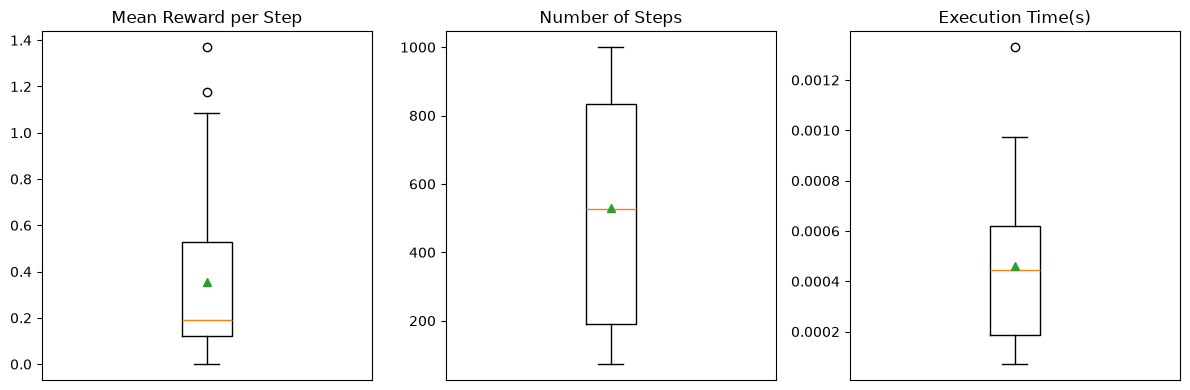

In [17]:
import matplotlib.pyplot as plt

cols = ["reward_per_step", "steps", "execution_time"]

titles = [
    "Mean Reward per Step",
    "Number of Steps",
    "Execution Time(s)"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, col, title in zip(axes, cols, titles):
    ax.boxplot(df_results[col], showmeans=True,)
    ax.set_title(title)
    ax.set_xticks([])

plt.tight_layout()
plt.show()    

## EX2


# a)

In [18]:
ALPHA = 0.7
GAMMA = 0.99

def create_q_table():
    return np.zeros((101, 4)) 

def update_q(Q, state, action_index, next_state):
    r = reward(next_state)

    if next_state == GOAL_STATE:
        best_future_q = 0

    else:
        best_future_q = np.max(Q[next_state])

    old_q = Q[state, action_index]
    new_q = ((1-ALPHA) * old_q + ALPHA * (r + GAMMA * best_future_q))

    Q[state, action_index] = new_q

Q = create_q_table()
print(Q.shape)

(101, 4)
